In [5]:
import re
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.sentiment.vader import SentimentIntensityAnalyzer

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from wordcloud import WordCloud

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('vader_lexicon')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


True

In [20]:

# QUESTION 1

raw_paragraph = (
    "Artificial intelligence is transforming modern technology at an unprecedented pace. "
    "Machine learning algorithms enable computers to learn efficiently from complex datasets. "
    "Deep learning neural networks solve intricate problems in computer vision and robotics. "
    "Natural language processing helps machines understand human speech and written text effectively. "
    "Ethical consideration and safety guidelines remain essential for sustainable technological development."
)

text_clean = raw_paragraph.lower()
text_no_punct = re.sub(r'[^\w\s]', '', text_clean)

sentences = sent_tokenize(raw_paragraph)
words_nltk = word_tokenize(text_no_punct)

print("--- Sentences ---")
for i, s in enumerate(sentences, 1):
    print(f"{i}. {s}")

python_split_words = text_clean.split()
print("\n--- Tokenization Comparison ---")
print("Python split() output (first 10):", python_split_words[:10])
print("NLTK word_tokenize() output (first 10):", words_nltk[:10])
print("\nDifference Explanation:")
print("Python split() splits strictly by whitespace and keeps trailing punctuation attached to words.")
print("NLTK word_tokenize() intelligently separates punctuation marks into distinct tokens and handles contractions.")

stop_words = set(stopwords.words('english'))
filtered_words = [w for w in words_nltk if w not in stop_words]

freq_dist = pd.Series(filtered_words).value_counts()
print("\n--- Word Frequency Distribution (Excluding Stopwords) ---")
print(freq_dist)

--- Sentences ---
1. Artificial intelligence is transforming modern technology at an unprecedented pace.
2. Machine learning algorithms enable computers to learn efficiently from complex datasets.
3. Deep learning neural networks solve intricate problems in computer vision and robotics.
4. Natural language processing helps machines understand human speech and written text effectively.
5. Ethical consideration and safety guidelines remain essential for sustainable technological development.

--- Tokenization Comparison ---
Python split() output (first 10): ['artificial', 'intelligence', 'is', 'transforming', 'modern', 'technology', 'at', 'an', 'unprecedented', 'pace.']
NLTK word_tokenize() output (first 10): ['artificial', 'intelligence', 'is', 'transforming', 'modern', 'technology', 'at', 'an', 'unprecedented', 'pace']

Difference Explanation:
Python split() splits strictly by whitespace and keeps trailing punctuation attached to words.
NLTK word_tokenize() intelligently separates punc

In [19]:
# QUESTION 2

alpha_words = re.findall(r'\b[a-zA-Z]+\b', text_clean)

alpha_filtered = [w for w in alpha_words if w not in stop_words]

stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(w) for w in alpha_filtered]

lemmatizer = WordNetLemmatizer()
lemmatized_words = [lemmatizer.lemmatize(w) for w in alpha_filtered]

comp_df = pd.DataFrame({
    'Original': alpha_filtered,
    'Stemmed': stemmed_words,
    'Lemmatized': lemmatized_words
})
print("--- Stemming vs Lemmatization Comparison (Sample) ---")
print(comp_df.drop_duplicates(subset=['Original']).head(12).to_string(index=False))

print("\n--- Analysis & Preference ---")
print("Stemming uses heuristic rules to chop off word ends, often producing non-words (e.g., 'learning' -> 'learn', 'guidelines' -> 'guidelin').")
print("Lemmatization uses a vocabulary and morphological analysis to return valid base dictionary forms (lemmas).")
print("Preference:")
print(" - Use Stemming when speed and simplicity matter most (e.g., quick search indexing, large-scale spam filtering).")
print(" - Use Lemmatization when semantic correctness and context matter (e.g., chatbot NLU, sentiment analysis, translation).")

--- Stemming vs Lemmatization Comparison (Sample) ---
     Original   Stemmed    Lemmatized
   artificial  artifici    artificial
 intelligence  intellig  intelligence
 transforming transform  transforming
       modern    modern        modern
   technology technolog    technology
unprecedented  unpreced unprecedented
         pace      pace          pace
      machine    machin       machine
     learning     learn      learning
   algorithms algorithm     algorithm
       enable     enabl        enable
    computers    comput      computer

--- Analysis & Preference ---
Stemming uses heuristic rules to chop off word ends, often producing non-words (e.g., 'learning' -> 'learn', 'guidelines' -> 'guidelin').
Lemmatization uses a vocabulary and morphological analysis to return valid base dictionary forms (lemmas).
Preference:
 - Use Stemming when speed and simplicity matter most (e.g., quick search indexing, large-scale spam filtering).
 - Use Lemmatization when semantic correctness and 

In [18]:

# QUESTION 3

short_texts = [
    "The new flagship smartphone features an amazing camera and long battery life.",
    "Stock market indices surged today as technology companies reported record earnings.",
    "The camera on this mobile device captures crystal clear photos and vibrant colors."
]

cv = CountVectorizer(stop_words='english')
bow_matrix = cv.fit_transform(short_texts)
print("--- Bag of Words Vocabulary ---")
print(cv.get_feature_names_out())

tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(short_texts)
feature_names = np.array(tfidf.get_feature_names_out())

print("\n--- Top 3 Keywords per Text (TF-IDF) ---")
for i, doc in enumerate(short_texts):
    row = tfidf_matrix[i].toarray().flatten()
    top_indices = row.argsort()[-3:][::-1]
    top_keywords = [(feature_names[idx], round(row[idx], 4)) for idx in top_indices]
    print(f"\nText {i+1}: \"{doc}\"")
    print(f"Top 3 Keywords: {top_keywords}")

print("\nInterpretation:")
print("TF-IDF highlights words that are frequent within a specific document but rare across the corpus.")
print("Text 1 focuses on hardware specs ('battery', 'life', 'amazing').")
print("Text 2 highlights financial market concepts ('earnings', 'indices', 'market').")
print("Text 3 emphasizes camera performance ('captures', 'clear', 'colors').")

--- Bag of Words Vocabulary ---
['amazing' 'battery' 'camera' 'captures' 'clear' 'colors' 'companies'
 'crystal' 'device' 'earnings' 'features' 'flagship' 'indices' 'life'
 'long' 'market' 'mobile' 'new' 'photos' 'record' 'reported' 'smartphone'
 'stock' 'surged' 'technology' 'today' 'vibrant']

--- Top 3 Keywords per Text (TF-IDF) ---

Text 1: "The new flagship smartphone features an amazing camera and long battery life."
Top 3 Keywords: [('smartphone', np.float64(0.3414)), ('new', np.float64(0.3414)), ('long', np.float64(0.3414))]

Text 2: "Stock market indices surged today as technology companies reported record earnings."
Top 3 Keywords: [('today', np.float64(0.3162)), ('technology', np.float64(0.3162)), ('surged', np.float64(0.3162))]

Text 3: "The camera on this mobile device captures crystal clear photos and vibrant colors."
Top 3 Keywords: [('vibrant', np.float64(0.3414)), ('photos', np.float64(0.3414)), ('mobile', np.float64(0.3414))]

Interpretation:
TF-IDF highlights words t

In [17]:

# QUESTION 4

tech_text_1 = (
    "Artificial intelligence leverages neural networks and deep learning models. "
    "It processes complex datasets to perform human-like perception tasks. "
    "Machine learning models automate pattern recognition and decision-making systems. "
    "Intelligent algorithms continue to transform computer science and robotics fields."
)

tech_text_2 = (
    "Blockchain technology provides decentralized and immutable ledger systems across networks. "
    "Smart contracts automate transactions without relying on central authorities. "
    "Cryptographic hashing guarantees security, transparency, and data integrity. "
    "Distributed network consensus ensures tamper-proof record keeping for financial assets."
)

def preprocess_text(text):
    text_clean = re.sub(r'[^\w\s]', '', text.lower())
    tokens = word_tokenize(text_clean)
    return [w for w in tokens if w not in stop_words]

tokens_1 = preprocess_text(tech_text_1)
tokens_2 = preprocess_text(tech_text_2)

set1, set2 = set(tokens_1), set(tokens_2)
jaccard_sim = len(set1.intersection(set2)) / len(set1.union(set2))

tfidf_sim_vectorizer = TfidfVectorizer(stop_words='english')
tfidf_sim_matrix = tfidf_sim_vectorizer.fit_transform([tech_text_1, tech_text_2])
cosine_sim = cosine_similarity(tfidf_sim_matrix[0:1], tfidf_sim_matrix[1:2])[0][0]

print(f"Jaccard Similarity Score: {jaccard_sim:.4f}")
print(f"Cosine Similarity Score : {cosine_sim:.4f}")

print("\n--- Metric Analysis ---")
print("In this scenario, Cosine Similarity gives better insights.")
print("Reasoning:")
print("1. Jaccard similarity relies purely on exact set overlap and treats all terms equally.")
print("2. Cosine similarity with TF-IDF accounts for term importance, document length, and word frequencies, providing a far more nuanced semantic comparison.")

Jaccard Similarity Score: 0.0508
Cosine Similarity Score : 0.0461

--- Metric Analysis ---
In this scenario, Cosine Similarity gives better insights.
Reasoning:
1. Jaccard similarity relies purely on exact set overlap and treats all terms equally.
2. Cosine similarity with TF-IDF accounts for term importance, document length, and word frequencies, providing a far more nuanced semantic comparison.


--- Sentiment Analysis Results ---
Sentiment  Compound Score                                                                                     Review
 Positive          0.9215 This laptop is outstanding! The battery life is amazing and display performance is superb.
 Negative         -0.7964 Terrible customer service. The product arrived broken and stopped working within two days.
  Neutral          0.0000    The smartphone is decent. It gets basic daily tasks done, though nothing extraordinary.
 Positive          0.3367      Highly recommended service! Extremely fast shipping and high quality software design.
 Negative         -0.7841                  Horrible experience, completely disappointed with the quality and delays.


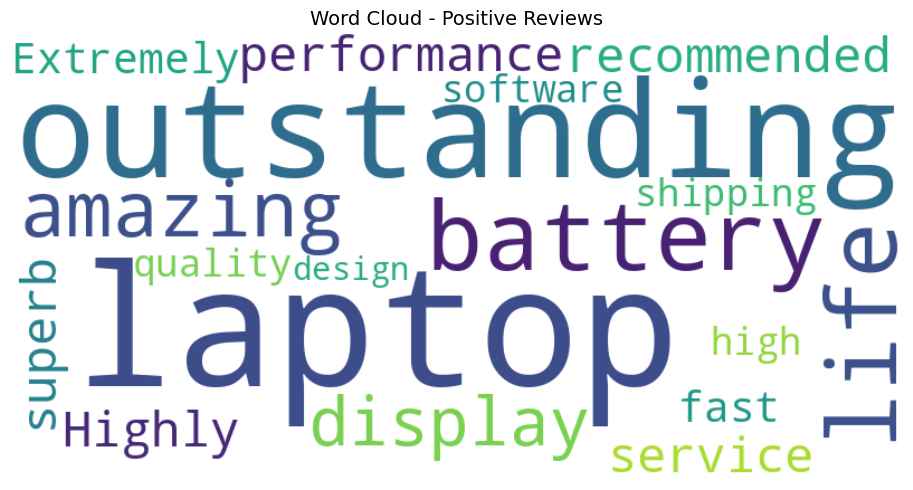

In [16]:

# QUESTION 5

reviews = [
    "This laptop is outstanding! The battery life is amazing and display performance is superb.",
    "Terrible customer service. The product arrived broken and stopped working within two days.",
    "The smartphone is decent. It gets basic daily tasks done, though nothing extraordinary.",
    "Highly recommended service! Extremely fast shipping and high quality software design.",
    "Horrible experience, completely disappointed with the quality and delays."
]

sia = SentimentIntensityAnalyzer()
results = []

for rev in reviews:
    scores = sia.polarity_scores(rev)
    compound = scores['compound']

    if compound >= 0.05:
        sentiment = 'Positive'
    elif compound <= -0.05:
        sentiment = 'Negative'
    else:
        sentiment = 'Neutral'

    results.append({
        'Review': rev,
        'Compound Score': compound,
        'Sentiment': sentiment
    })

rev_df = pd.DataFrame(results)
print("--- Sentiment Analysis Results ---")
print(rev_df[['Sentiment', 'Compound Score', 'Review']].to_string(index=False))

positive_reviews_text = " ".join(rev_df[rev_df['Sentiment'] == 'Positive']['Review'])

wc = WordCloud(width=800, height=400, background_color='white').generate(positive_reviews_text)

plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud - Positive Reviews', fontsize=14)
plt.tight_layout()
plt.show()

In [14]:
# QUESTION 6
train_paragraph = (
    "Artificial intelligence is rapidly changing the world of technology and computing. "
    "Machine learning allows systems to learn from data and improve performance automatically. "
    "Deep learning utilizes artificial neural networks to analyze complex patterns. "
    "Natural language processing helps computers understand human language effortlessly. "
    "Data science provides valuable insights through intelligent statistical analysis. "
    "Automation streamlines industry workflows and creates futuristic technological innovations."
)


tokenizer.fit_on_texts([train_paragraph])
total_words = len(tokenizer.word_index) + 1


input_sequences = []
for line in train_paragraph.split('.'):
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(token_list)):
        n_gram_sequence = token_list[:i+1]
        input_sequences.append(n_gram_sequence)

max_sequence_len = max([len(x) for x in input_sequences])
padded_sequences = pad_sequences(input_sequences, maxlen=max_sequence_len, padding='pre')

X = padded_sequences[:, :-1]
y = tf.keras.utils.to_categorical(padded_sequences[:, -1], num_classes=total_words)


model = Sequential([
    Embedding(total_words, 32, input_length=max_sequence_len - 1),
    LSTM(64),
    Dense(total_words, activation='softmax')
])

model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.fit(X, y, epochs=120, verbose=0)
print("Keras LSTM model trained successfully!")


def generate_text(seed_word, next_words, max_seq_len):
    output_text = seed_word
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([output_text])[0]
        token_list = pad_sequences([token_list], maxlen=max_seq_len-1, padding='pre')
        predicted_probs = model.predict(token_list, verbose=0)
        predicted_word_idx = np.argmax(predicted_probs, axis=-1)[0]

        output_word = ""
        for word, index in tokenizer.word_index.items():
            if index == predicted_word_idx:
                output_word = word
                break
        output_text += " " + output_word
    return output_text


seed_1 = "artificial"
seed_2 = "deep"
seed_3 = "data"

print("\n--- Generated Text Sequences ---")
print("Seed 1 ('artificial'):", generate_text(seed_1, 7, max_sequence_len))
print("Seed 2 ('deep')      :", generate_text(seed_2, 8, max_sequence_len))
print("Seed 3 ('data')      :", generate_text(seed_3, 7, max_sequence_len))

Keras LSTM model trained successfully!

--- Generated Text Sequences ---
Seed 1 ('artificial'): artificial learning is rapidly changing the world of
Seed 2 ('deep')      : deep learning utilizes artificial neural networks to analyze complex
Seed 3 ('data')      : data learning artificial neural neural to analyze complex
